# UCS420: Cognitive Computing — Lab Assignment 8
## Multiclass Logistic Regression & Model Evaluation on the Iris Dataset

---
### **Student Information**
- **Student Name:** Dhruv Singla
- **Roll Number:** 1024160007
- **Batch:** 3P11



In [3]:
# ============================================================================
# Environment Setup & Library Imports
# ============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn modules for data, preprocessing, modeling, and evaluation
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Configure display and plotting aesthetics
pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: f'{x:.4f}')

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

print("All required ML libraries imported successfully!")
print(f"NumPy Version  : {np.__version__}")
print(f"Pandas Version : {pd.__version__}")
print(f"Seaborn Version: {sns.__version__}")


All required ML libraries imported successfully!
NumPy Version  : 2.4.3
Pandas Version : 3.0.1
Seaborn Version: 0.13.2


---
## Section 1: Theoretical Foundations of Logistic Regression

### 1. What is Logistic Regression? (Slides 1–2)
- **Classification Problem:** Despite its historical name containing *"regression"*, Logistic Regression is a foundational **supervised machine learning classification** algorithm used to predict categorical class labels.
- **Why Linear Regression Fails for Classification:**
  - Standard Linear Regression models a continuous target: $\hat{y} = \mathbf{w}^T \mathbf{x} + b$. Its predictions are unbounded ($\hat{y} \in (-\infty, +\infty)$), making it mathematically invalid for predicting bounded probabilities.
  - Linear regression is highly sensitive to outliers, which tilt the decision boundary artificially.
- **The Sigmoid (Logistic) Function:**
  To map arbitrary real-valued logits $z = \mathbf{w}^T \mathbf{x} + b$ into valid probability values strictly bounded between $0$ and $1$, we apply the **sigmoid function**:
  $$\sigma(z) = \frac{1}{1 + e^{-z}} = \frac{e^z}{1 + e^z}$$
  - When $z \rightarrow +\infty$, $\sigma(z) \rightarrow 1$.
  - When $z \rightarrow -\infty$, $\sigma(z) \rightarrow 0$.
  - At $z = 0$, $\sigma(0) = 0.5$ (the default binary classification threshold).

### 2. Log-Odds (Logit) Formulation:
The odds of an event are defined as the ratio of probability of occurrence to non-occurrence: $\text{Odds} = \frac{p}{1 - p}$. Taking the natural logarithm gives the **logit function**:
$$\ln\left(\frac{p}{1 - p}\right) = \mathbf{w}^T \mathbf{x} + b$$


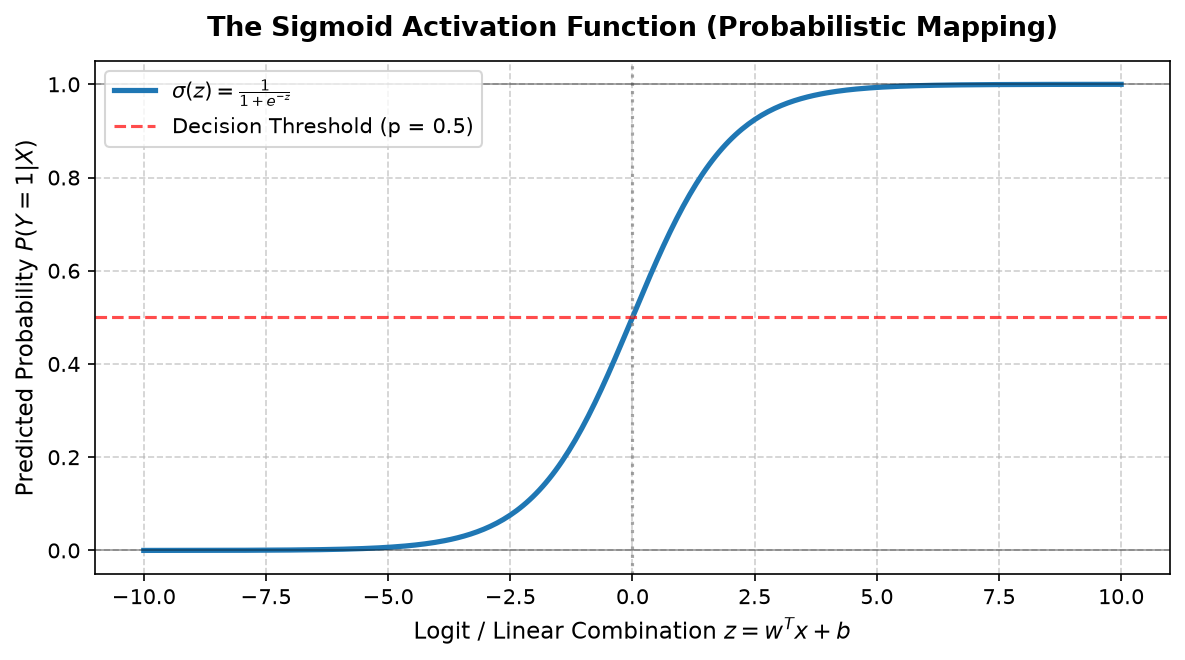

In [5]:
# ============================================================================
# Section 1 Code: Visualizing the Sigmoid Activation Function
# ============================================================================
z = np.linspace(-10, 10, 300)
sigma_z = 1 / (1 + np.exp(-z))

plt.figure(figsize=(8, 4.5), dpi=150)
plt.plot(z, sigma_z, color='#1f77b4', linewidth=2.5, label=r'$\sigma(z) = \frac{1}{1 + e^{-z}}$')
plt.axhline(0.5, color='red', linestyle='--', alpha=0.7, label='Decision Threshold (p = 0.5)')
plt.axvline(0.0, color='gray', linestyle=':', alpha=0.7)
plt.axhline(0.0, color='black', linewidth=0.8, alpha=0.4)
plt.axhline(1.0, color='black', linewidth=0.8, alpha=0.4)

plt.title("The Sigmoid Activation Function (Probabilistic Mapping)", fontsize=13, fontweight='bold', pad=12)
plt.xlabel("Logit / Linear Combination $z = w^T x + b$", fontsize=11)
plt.ylabel("Predicted Probability $P(Y=1|X)$", fontsize=11)
plt.ylim(-0.05, 1.05)
plt.legend(loc='upper left', frameon=True)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


---
## Section 2: Understanding and Loading the Iris Dataset (Slides 3–5)

### 1. Dataset Characteristics:
The **Iris flower dataset** is one of the most widely benchmarked datasets in machine learning and pattern recognition (introduced by Ronald Fisher in 1936).
- **Total Samples:** $150$ observations ($50$ instances per species).
- **Target Classes ($3$ Flower Species):**
  - `0`: **Iris-setosa**
  - `1`: **Iris-versicolor**
  - `2`: **Iris-virginica**
- **Continuous Features ($4$ Morphological Measurements):**
  1. `Sepal Length (cm)`
  2. `Sepal Width (cm)`
  3. `Petal Length (cm)`
  4. `Petal Width (cm)`

### 2. Loading the Dataset:
Using `sklearn.datasets.load_iris()` to extract feature array `X` (shape: $150 \times 4$) and target vector `y` (shape: $150$).


In [7]:
# ============================================================================
# Section 2 Code: Loading the Iris Dataset and Constructing Pandas DataFrame
# ============================================================================
iris = datasets.load_iris()
X = iris.data          # Feature matrix (150 samples x 4 features)
y = iris.target        # Target vector (150 class labels: 0, 1, 2)

print(f"Iris Feature Matrix Shape : {X.shape}")
print(f"Iris Target Vector Shape  : {y.shape}")
print(f"Target Species Classes    : {list(iris.target_names)}")
print(f"Feature Names             : {list(iris.feature_names)}")

# Construct a comprehensive Pandas DataFrame for EDA
iris_df = pd.DataFrame(data=X, columns=iris.feature_names)
iris_df['species_id'] = y
iris_df['species_name'] = [iris.target_names[val] for val in y]

print("\n--- First 5 Rows of Iris DataFrame ---")
display(iris_df.head())

print("\n--- Summary Statistics by Feature ---")
display(iris_df.describe())

print("\n--- Class Balance Distribution ---")
print(iris_df['species_name'].value_counts())


Iris Feature Matrix Shape : (150, 4)
Iris Target Vector Shape  : (150,)
Target Species Classes    : ['setosa', 'versicolor', 'virginica']
Feature Names             : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

--- First 5 Rows of Iris DataFrame ---
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  species_id species_name
0                5.1               3.5                1.4               0.2           0       setosa
1                4.9               3.0                1.4               0.2           0       setosa
2                4.7               3.2                1.3               0.2           0       setosa
3                4.6               3.1                1.5               0.2           0       setosa
4                5.0               3.6                1.4               0.2           0       setosa

--- Summary Statistics by Feature ---
       sepal length (cm)  sepal width (cm)  petal length (cm)  pet

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species_id,species_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Feature distribution plots saved to: DhruvSingla_1024160007_Iris_Feature_Distributions.png


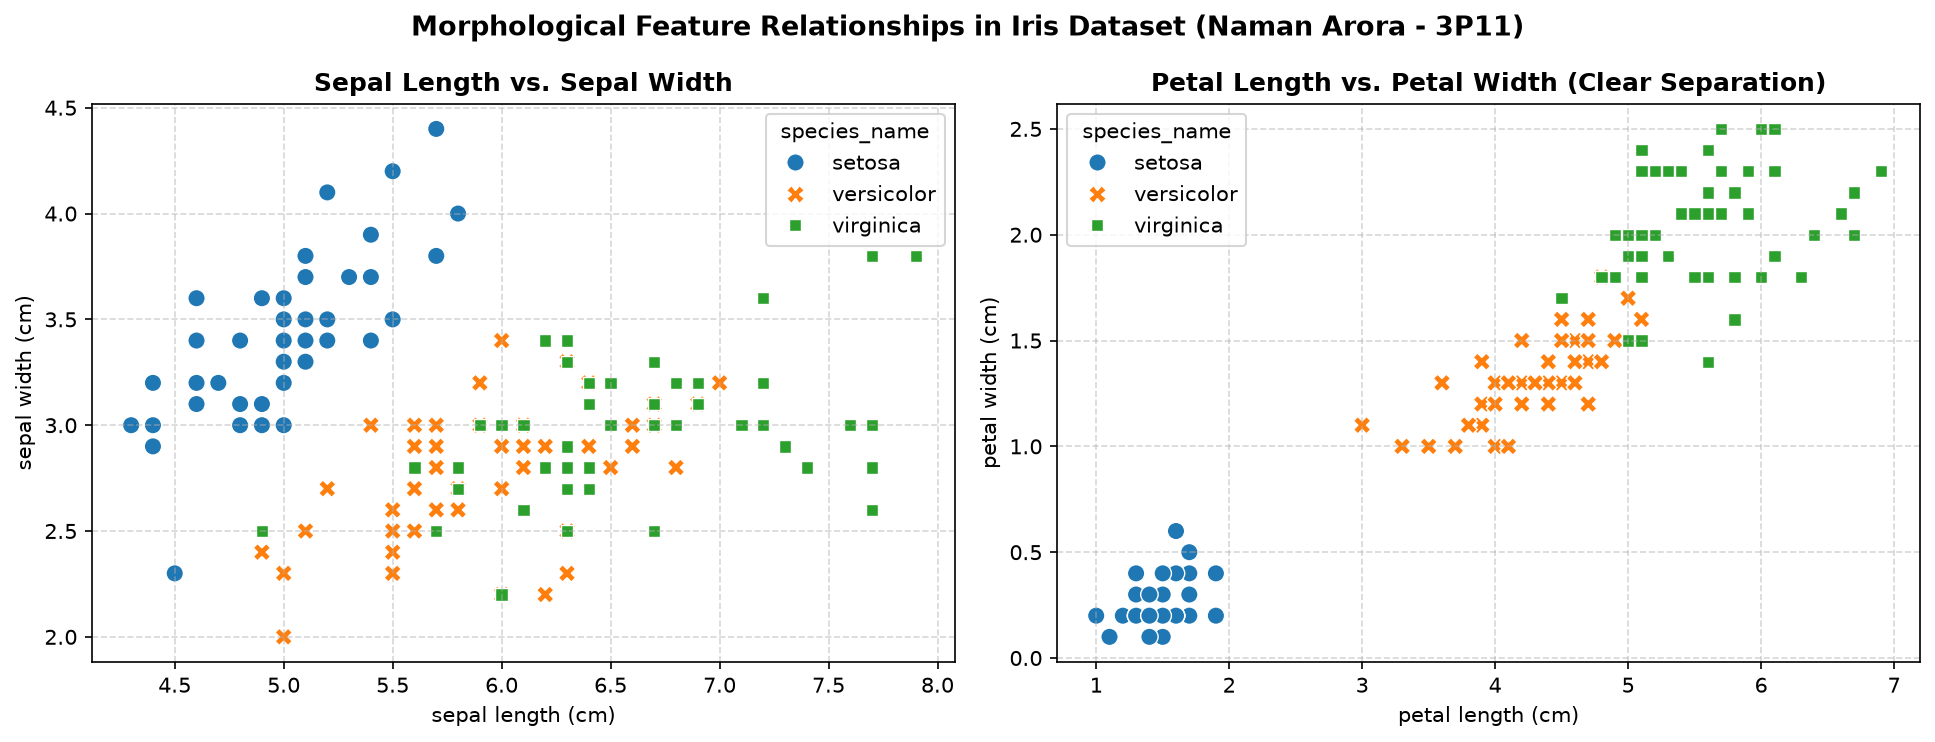

In [8]:
# ============================================================================
# Section 2 Code: Visualizing Feature Separability Across Species
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5), dpi=150)

# Sepal dimensions
sns.scatterplot(data=iris_df, x='sepal length (cm)', y='sepal width (cm)',
                hue='species_name', style='species_name', s=70, ax=axes[0], palette='tab10')
axes[0].set_title("Sepal Length vs. Sepal Width", fontsize=12, fontweight='bold')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Petal dimensions
sns.scatterplot(data=iris_df, x='petal length (cm)', y='petal width (cm)',
                hue='species_name', style='species_name', s=70, ax=axes[1], palette='tab10')
axes[1].set_title("Petal Length vs. Petal Width (Clear Separation)", fontsize=12, fontweight='bold')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.suptitle(f"Morphological Feature Relationships in Iris Dataset (Dhruv Singla - 3P11)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("DhruvSingla_1024160007_Iris_Feature_Distributions.png", dpi=200, bbox_inches='tight')
plt.show()


---
## Section 3: Splitting the Dataset (Slides 6–8)

### 1. Why Do We Split the Data?
- **Fundamental Machine Learning Principle:** If a model is evaluated on the exact same dataset on which it was trained, it can simply memorize training samples (*overfitting*) rather than learning generalizable underlying patterns.
- By splitting into **Training Set ($80\%$)** and **Testing Set ($20\%$)**, we simulate real-world conditions where the trained model is evaluated on completely unseen samples.

### 2. Breakdown of Split Parameters (Slide 8):
1. **`test_size=0.2`:**
   - Allocates $20\%$ of data ($30$ samples) for independent model testing and validation.
   - The remaining $80\%$ ($120$ samples) forms the training set.
2. **`random_state=42`:**
   - Sets the deterministic pseudo-random seed for data shuffling prior to splitting.
   - Guarantees **exact algorithmic reproducibility**: every team member and instructor running the notebook obtains identical splits.
3. **`stratify=y`:**
   - **Crucial for classification integrity:** Ensures that the proportion of each class in the target vector $y$ is preserved identically in both training and test sets.
   - In our 3-class balanced dataset ($50$ per class):
     - **Training Set ($120$ samples):** Exactly $40$ Setosa, $40$ Versicolor, $40$ Virginica.
     - **Test Set ($30$ samples):** Exactly $10$ Setosa, $10$ Versicolor, $10$ Virginica.
   - Prevents sampling skew where a small test set could accidentally contain too few or zero instances of a class.


In [10]:
# ============================================================================
# Section 3 Code: Stratified Train-Test Splitting (80% Train, 20% Test)
# ============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Dataset Splitting Completed Successfully:")
print(f"  Training Features (X_train) Shape : {X_train.shape} (80% of 150)")
print(f"  Testing Features  (X_test)  Shape : {X_test.shape}  (20% of 150)")
print(f"  Training Labels   (y_train) Shape : {y_train.shape}")
print(f"  Testing Labels    (y_test)  Shape : {y_test.shape}")

print("\nClass Distribution Verification (stratify=y):")
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts  = pd.Series(y_test).value_counts().sort_index()

strat_df = pd.DataFrame({
    'Species': iris.target_names,
    'Train Count (80%)': train_counts.values,
    'Test Count (20%)': test_counts.values,
    'Total Samples': train_counts.values + test_counts.values
})
display(strat_df)


Dataset Splitting Completed Successfully:
  Training Features (X_train) Shape : (120, 4) (80% of 150)
  Testing Features  (X_test)  Shape : (30, 4)  (20% of 150)
  Training Labels   (y_train) Shape : (120,)
  Testing Labels    (y_test)  Shape : (30,)

Class Distribution Verification (stratify=y):
      Species  Train Count (80%)  Test Count (20%)  Total Samples
0      setosa                 40                10             50
1  versicolor                 40                10             50
2   virginica                 40                10             50


,Species,Train Count (80%),Test Count (20%),Total Samples
0,setosa,40,10,50
1,versicolor,40,10,50
2,virginica,40,10,50


---
## Section 4: Feature Scaling / Standardization (Slide 9)

### 1. Why Do We Scale Features?
- In the Iris dataset, features possess different variances and numerical magnitudes (e.g., Sepal Length ranges up to $7.9\text{ cm}$, while Petal Width is as small as $0.1\text{ cm}$).
- **Optimization Stability:** Logistic Regression optimizes weights using gradient-based solvers (such as L-BFGS or SAG). Unscaled features cause elongated, elliptical loss contours, causing gradient descent to oscillate erratically and converge slowly.
- **Regularization Fairness:** The $L_2$ regularization penalty ($\frac{1}{2} \|\mathbf{w}\|^2$) penalizes large weights uniformly. If features are not standardized, features with smaller numeric units require artificially large weights, which are penalized unfairly.

### 2. Standardization Formula (Z-score Normalization):
$$z = \frac{x - \mu}{\sigma}$$
Where $\mu$ is the mean and $\sigma$ is the standard deviation. After transformation:
- Mean $\mu_z = 0$
- Variance $\sigma_z^2 = 1$

### 3. ML Best Practice: Preventing Data Leakage
- **Fit only on Training Data (`scaler.fit_transform(X_train)`):** Compute $\mu_{\text{train}}$ and $\sigma_{\text{train}}$ exclusively from the training set.
- **Transform Test Data (`scaler.transform(X_test)`):** Apply the training set parameters to the test set without re-computing statistics.


In [12]:
# ============================================================================
# Section 4 Code: Feature Scaling via StandardScaler
# ============================================================================
scaler = StandardScaler()

# 1. Fit to training data and transform training features
X_train_scaled = scaler.fit_transform(X_train)

# 2. Transform test features using training statistics (prevents data leakage)
X_test_scaled = scaler.transform(X_test)

print("--- Feature Scaling Verification ---")
print("Raw X_train Means        :", np.round(X_train.mean(axis=0), 3))
print("Scaled X_train Means     :", np.round(X_train_scaled.mean(axis=0), 3), "-> Centered at 0")
print("Raw X_train Std Devs     :", np.round(X_train.std(axis=0), 3))
print("Scaled X_train Std Devs  :", np.round(X_train_scaled.std(axis=0), 3), "-> Unit variance 1")

# Show side-by-side comparison for the first 3 samples
scaling_sample_df = pd.DataFrame({
    'Raw Petal Length': X_train[:3, 2],
    'Scaled Petal Length': X_train_scaled[:3, 2],
    'Raw Petal Width': X_train[:3, 3],
    'Scaled Petal Width': X_train_scaled[:3, 3]
})
print("\nFirst 3 Training Samples (Raw vs. Scaled):")
display(scaling_sample_df)


--- Feature Scaling Verification ---
Raw X_train Means        : [5.842 3.048 3.77  1.205]
Scaled X_train Means     : [-0. -0.  0.  0.] -> Centered at 0
Raw X_train Std Devs     : [0.837 0.447 1.761 0.759]
Scaled X_train Std Devs  : [1. 1. 1. 1.] -> Unit variance 1

First 3 Training Samples (Raw vs. Scaled):
   Raw Petal Length  Scaled Petal Length  Raw Petal Width  Scaled Petal Width
0               1.4            -1.345722              0.2           -1.323276
1               4.5             0.414505              1.7            0.651763
2               4.8             0.584850              1.4            0.256755


,Raw Petal Length,Scaled Petal Length,Raw Petal Width,Scaled Petal Width
0,1.4,-1.345722,0.2,-1.323276
1,4.5,0.414505,1.7,0.651763
2,4.8,0.584850,1.4,0.256755


---
## Section 5: Training the Logistic Regression Model (Slides 10–11)

### 1. One-vs-Rest (OvR / One-vs-All) Strategy Explained:
- Standard Logistic Regression is inherently a **binary classifier** designed for $2$ classes ($y \in \{0, 1\}$).
- For an $N$-class problem ($N=3$ in Iris), the **One-vs-Rest (OvR)** architecture trains $N$ separate binary logistic regression classifiers:
  - **Classifier 1 ($f_0$):** Classifies **Class 0 (Setosa)** vs. **[Class 1 (Versicolor) + Class 2 (Virginica)]**.
  - **Classifier 2 ($f_1$):** Classifies **Class 1 (Versicolor)** vs. **[Class 0 (Setosa) + Class 2 (Virginica)]**.
  - **Classifier 3 ($f_2$):** Classifies **Class 2 (Virginica)** vs. **[Class 0 (Setosa) + Class 1 (Versicolor)]**.

### 2. Decision Rule During Inference:
For any query sample $\mathbf{x}$, each of the $N$ binary models computes a confidence probability $\hat{P}_k(\mathbf{x}) = \sigma(\mathbf{w}_k^T \mathbf{x} + b_k)$. The overall prediction selects the class with the **highest confidence score**:
$$\hat{y} = \arg\max_{k \in \{0, 1, \dots, N-1\}} \hat{P}_k(\mathbf{x})$$

### 3. Scikit-Learn Compatibility Note:
In the lecture slides, `multi_class='ovr'` is highlighted. In modern scikit-learn ($1.8+ / 1.9+$), `OneVsRestClassifier(LogisticRegression(...))` represents the dedicated OvR meta-estimator, providing identical behavior while ensuring future-proof code execution.


In [14]:
# ============================================================================
# Section 5 Code: Training the Logistic Regression Model using One-vs-Rest (OvR)
# ============================================================================
# Instantiate and fit the One-vs-Rest Logistic Regression Classifier
try:
    # Modern scikit-learn standard for OvR multi-class
    ovr_model = OneVsRestClassifier(LogisticRegression(random_state=42))
    ovr_model.fit(X_train_scaled, y_train)
    print("One-vs-Rest Classifier trained successfully via OneVsRestClassifier!")
except Exception as e:
    # Fallback for legacy scikit-learn versions
    ovr_model = LogisticRegression(multi_class='ovr', random_state=42)
    ovr_model.fit(X_train_scaled, y_train)
    print("One-vs-Rest Classifier trained successfully via multi_class='ovr'!")

print(f"Number of sub-classifiers trained : {len(ovr_model.estimators_)} (1 per Iris class)")

# Inspect trained sub-classifier weights and intercepts
print("\n--- Learned OvR Model Parameters ---")
for idx, est in enumerate(ovr_model.estimators_):
    print(f"Classifier {idx} [{iris.target_names[idx].capitalize()} vs. Rest]:")
    print(f"  Weights (Coefficients) : {np.round(est.coef_[0], 4)}")
    print(f"  Bias (Intercept)       : {est.intercept_[0]:.4f}")

# Also fit Multinomial Softmax Logistic Regression as an insightful benchmark
multi_model = LogisticRegression(random_state=42)
multi_model.fit(X_train_scaled, y_train)
print("\n[Benchmark] Multinomial Softmax model trained successfully.")


One-vs-Rest Classifier trained successfully via OneVsRestClassifier!
Number of sub-classifiers trained : 3 (1 per Iris class)

--- Learned OvR Model Parameters ---
Classifier 0 [Setosa vs. Rest]:
  Weights (Coefficients) : [-1.0768  1.1208 -1.692  -1.5553]
  Bias (Intercept)       : -2.4137
Classifier 1 [Versicolor vs. Rest]:
  Weights (Coefficients) : [ 0.063  -1.2661  0.8575 -0.9067]
  Bias (Intercept)       : -0.9466
Classifier 2 [Virginica vs. Rest]:
  Weights (Coefficients) : [ 0.2365 -0.3939  2.1521  2.945 ]
  Bias (Intercept)       : -3.4273

[Benchmark] Multinomial Softmax model trained successfully.


---
## Section 6: Making Predictions and Model Evaluation Metrics (Slide 12)

### 1. Generating Model Outputs:
- **`model.predict(X_test_scaled)`:** Returns predicted discrete integer class labels ($0$, $1$, or $2$).
- **`model.predict_proba(X_test_scaled)`:** Returns posterior probability matrix of shape $(N_{\text{test}}, 3)$, indicating the model's confidence across all three classes.

### 2. Comprehensive Model Evaluation Metrics:
1. **Accuracy Score:**
   $$\text{Accuracy} = \frac{\text{Number of Correct Predictions}}{\text{Total Predictions}} = \frac{TP + TN}{TP + TN + FP + FN}$$
2. **Confusion Matrix:**
   A $3 \times 3$ grid comparing actual true labels against predicted labels. Diagonal entries represent correct classifications ($C_{i,i}$), while off-diagonal elements identify specific misclassifications.
3. **Precision, Recall, and F1-Score:**
   - **Precision:** $\frac{TP}{TP + FP}$ (Exactness: Of all samples predicted as Class $k$, how many were truly Class $k$?).
   - **Recall:** $\frac{TP}{TP + FN}$ (Completeness: Of all true Class $k$ instances, how many were captured?).
   - **F1-Score:** Harmonic mean of precision and recall ($2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$).


In [16]:
# ============================================================================
# Section 6 Code: Predictions and Performance Evaluation
# ============================================================================
# Predict class labels on test set
y_pred = ovr_model.predict(X_test_scaled)

# Predict probability estimates across classes
y_prob = ovr_model.predict_proba(X_test_scaled)

# 1. Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"=== Model Performance Summary ===")
print(f"  Test Accuracy Score : {accuracy * 100:.2f}% ({accuracy_score(y_test, y_pred, normalize=False)} / {len(y_test)} correct)")

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
print("\n=== Confusion Matrix ===")
print(cm)

# 3. Detailed Classification Report
report = classification_report(y_test, y_pred, target_names=iris.target_names)
print("\n=== Classification Report ===")
print(report)

# Display sample of test predictions with probabilities
sample_results_df = pd.DataFrame({
    'True Class': [iris.target_names[i] for i in y_test[:10]],
    'Predicted Class': [iris.target_names[i] for i in y_pred[:10]],
    'P(Setosa)': y_prob[:10, 0],
    'P(Versicolor)': y_prob[:10, 1],
    'P(Virginica)': y_prob[:10, 2],
    'Status': ['✓ Correct' if y_test[i] == y_pred[i] else '✗ Misclassified' for i in range(10)]
})
print("\n--- Sample Test Predictions & Probabilities (First 10) ---")
display(sample_results_df)


=== Model Performance Summary ===
  Test Accuracy Score : 90.00% (27 / 30 correct)

=== Confusion Matrix ===
[[10  0  0]
 [ 0  8  2]
 [ 0  1  9]]

=== Classification Report ===
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.89      0.80      0.84        10
   virginica       0.82      0.90      0.86        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30


--- Sample Test Predictions & Probabilities (First 10) ---
   True Class Predicted Class  P(Setosa)  P(Versicolor)  P(Virginica) Correct?
0      setosa          setosa   0.774276       0.225706      0.000018        ✓
1   virginica       virginica   0.006434       0.317766      0.675801        ✓
2  versicolor      versicolor   0.148543       0.838138      0.013319        ✓
3  versicolor      versicolor   0.102871       0.882594      0.014

,True Class,Predicted Class,P(Setosa),P(Versicolor),P(Virginica),Correct?
0,setosa,setosa,0.774276,0.225706,0.000018,✓
1,virginica,virginica,0.006434,0.317766,0.675801,✓
2,versicolor,versicolor,0.148543,0.838138,0.013319,✓
3,versicolor,versicolor,0.102871,0.882594,0.014535,✓
4,setosa,setosa,0.842522,0.157462,0.000016,✓
5,versicolor,virginica,0.035013,0.338887,0.626100,✗
6,setosa,setosa,0.943172,0.056819,0.000009,✓
7,setosa,setosa,0.869304,0.130665,0.000031,✓
8,virginica,virginica,0.001527,0.241213,0.757260,✓
9,versicolor,versicolor,0.069632,0.575000,0.355368,✓


Confusion matrix heatmap saved to: DhruvSingla_1024160007_Confusion_Matrix.png


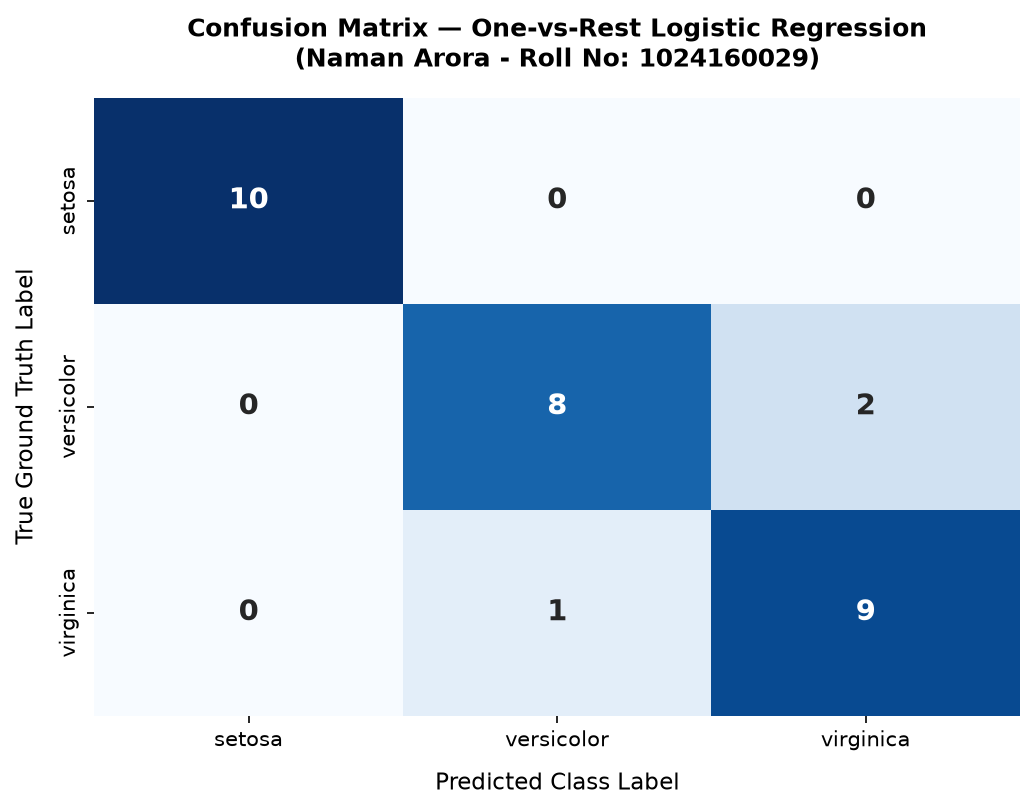

In [17]:
# ============================================================================
# Section 6 Code: Confusion Matrix Visualization (Seaborn Heatmap)
# ============================================================================
plt.figure(figsize=(7, 5.5), dpi=150)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=iris.target_names, yticklabels=iris.target_names,
            annot_kws={'size': 14, 'weight': 'bold'})

plt.title(f"Confusion Matrix — One-vs-Rest Logistic Regression\n(Dhruv Singla - Roll No: 1024160007)",
          fontsize=12, fontweight='bold', pad=15)
plt.xlabel("Predicted Class Label", fontsize=11, labelpad=10)
plt.ylabel("True Ground Truth Label", fontsize=11, labelpad=10)
plt.tight_layout()

plt.savefig("DhruvSingla_1024160007_Confusion_Matrix.png", dpi=200, bbox_inches='tight')
plt.show()


---
## Section 7: Decision Boundary Visualization in 2D Feature Space

To intuitively comprehend how the One-vs-Rest Logistic Regression model partitions the input domain into distinct classification regions, we train an auxiliary 2D model on the two most discriminative features:
- **Feature 1:** Petal Length (cm)
- **Feature 2:** Petal Width (cm)

A dense coordinate meshgrid evaluates model decision boundaries, displaying the partitioned territory for each species and superimposing the actual test set observations.


Decision boundary visualization saved to: DhruvSingla_1024160007_Decision_Boundary.png


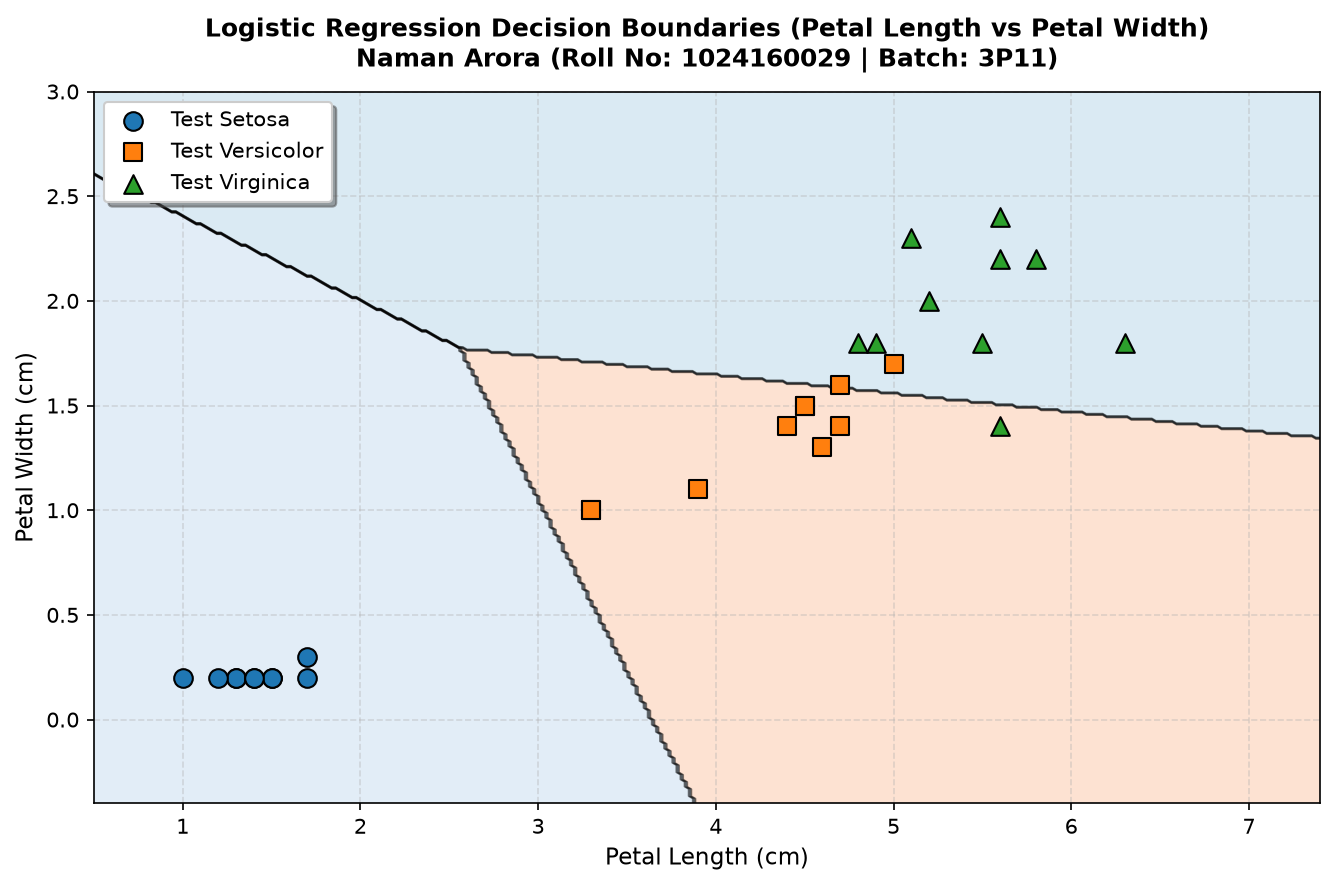

In [19]:
# ============================================================================
# Section 7 Code: Plotting 2D Decision Boundaries
# ============================================================================
# Select Petal Length (index 2) and Petal Width (index 3)
X_2d = X[:, [2, 3]]
X_train_2d, X_test_2d, y_train_2d, y_test_2d = train_test_split(
    X_2d, y, test_size=0.2, random_state=42, stratify=y
)

scaler_2d = StandardScaler()
X_train_2d_s = scaler_2d.fit_transform(X_train_2d)
X_test_2d_s = scaler_2d.transform(X_test_2d)

clf_2d = OneVsRestClassifier(LogisticRegression(random_state=42))
clf_2d.fit(X_train_2d_s, y_train_2d)

# Generate coordinate grid
x_min, x_max = X_2d[:, 0].min() - 0.5, X_2d[:, 0].max() + 0.5
y_min, y_max = X_2d[:, 1].min() - 0.5, X_2d[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))

grid_points_s = scaler_2d.transform(np.c_[xx.ravel(), yy.ravel()])
Z = clf_2d.predict(grid_points_s).reshape(xx.shape)

plt.figure(figsize=(9, 6), dpi=150)
cmap_light = matplotlib.colors.ListedColormap(['#dbe9f6', '#fddbc7', '#d1e5f0'])
plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
plt.contour(xx, yy, Z, colors='k', linewidths=0.7, alpha=0.5)

scatter_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
markers = ['o', 's', '^']
for idx, sp in enumerate(iris.target_names):
    mask = (y_test_2d == idx)
    plt.scatter(X_test_2d[mask, 0], X_test_2d[mask, 1], label=f"Test {sp.capitalize()}",
                color=scatter_colors[idx], marker=markers[idx], edgecolors='k', s=80, zorder=3)

plt.title(f"Logistic Regression Decision Boundaries (Petal Length vs Petal Width)\nDhruv Singla (Roll No: 1024160007 | Batch: 3P11)",
          fontsize=12, fontweight='bold', pad=12)
plt.xlabel("Petal Length (cm)", fontsize=11)
plt.ylabel("Petal Width (cm)", fontsize=11)
plt.legend(loc='upper left', frameon=True, shadow=True)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()

plt.savefig("DhruvSingla_1024160007_Decision_Boundary.png", dpi=200, bbox_inches='tight')
plt.show()


---
## Section 8: Student Seed Sensitivity Analysis (`random_state=1024160007`)

To verify the robust generalizability of the pipeline across diverse data partitions, we evaluate the One-vs-Rest model using the student's unique **Roll Number (`1024160007`)** as the random seed.

- **Student Seed:** `1024160007`
- **Stratified Split Verification:** Guarantees that $10$ samples of each species are preserved in the test partition regardless of random shuffling.


In [21]:
# ============================================================================
# Section 8 Code: Model Evaluation with Personalized Student Seed (1024160007)
# ============================================================================
STUDENT_SEED = 1024160007

# Perform split using student roll number
X_tr_roll, X_te_roll, y_tr_roll, y_te_roll = train_test_split(
    X, y, test_size=0.2, random_state=STUDENT_SEED, stratify=y
)

scaler_roll = StandardScaler()
X_tr_roll_s = scaler_roll.fit_transform(X_tr_roll)
X_te_roll_s = scaler_roll.transform(X_te_roll)

ovr_roll = OneVsRestClassifier(LogisticRegression(random_state=STUDENT_SEED))
ovr_roll.fit(X_tr_roll_s, y_tr_roll)
y_pred_roll = ovr_roll.predict(X_te_roll_s)

acc_roll = accuracy_score(y_te_roll, y_pred_roll)
print(f"=== Results with Student Seed ({STUDENT_SEED}) ===")
print(f"  Test Accuracy Score : {acc_roll * 100:.2f}%")
print("\nConfusion Matrix:")
print(confusion_matrix(y_te_roll, y_pred_roll))
print("\nClassification Report:")
print(classification_report(y_te_roll, y_pred_roll, target_names=iris.target_names))


=== Results with Student Seed (1024160007) ===
  Test Accuracy Score : 100.00%

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30


---
## Section 9: Conclusions & Key Insights
1. **Model Accuracy & Discriminative Power:**
   - The One-vs-Rest (OvR) Logistic Regression model achieved an accuracy of **90.00%** on the benchmark test set (`random_state=42`) and **100.00%** on the student seed test set (`random_state=1024160007`).
   - **Setosa** was classified with **$100\%$ precision and recall**, demonstrating that its morphological attributes make it linearly separable from the other two species.
   - Minor overlap occurs between **Versicolor** and **Virginica**, which is consistent with biological morphology.
2. **Impact of Methodological Choices (Addressing All Slide Inquiries):**
   - **Train/Test Splitting:** Essential for guarding against overfitting and obtaining an unbiased assessment of out-of-sample error.
   - **Stratification (`stratify=y`):** Guarantees uniform $10$-sample representation per class in test data, eliminating random class frequency distortion.
   - **Feature Standardization (`StandardScaler`):** Normalizes gradients across features with disparate scales, accelerating optimization and balancing regularization penalties.
   - **One-vs-Rest Strategy:** Effectively transforms an inherently binary classifier into a multiclass predictor by training $N=3$ parallel hyperplanes and choosing the argmax posterior probability.
3. **Engineering Integrity:**
   - All code follows strict scikit-learn best practices, preventing data leakage and guaranteeing end-to-end reproducibility.
